# OpenCV 培训大作业 · 奶蛙自动检测与标注系统

> RobotIC 算法组 · 新人培训第一讲 · **综合大作业**
> 覆盖必修讲义第 1～11 章的主要内容 ｜ 满分 90 分

---

## 背景

算法组要给《奶蛙圣殿巡行》的剧照做一个**自动标注工具**：
输入一张图，程序要能自动找到画面里的奶蛙、把它框出来、打上标签。

这段片子有个麻烦的地方 —— 奶蛙一会儿在亮堂堂的白底名画里，
一会儿又潜进昏暗的水下，**光照变化极大**。
你要做的，就是找一个"光照变了也照样认得出来"的办法。

## 交付要求

| 项 | 要求 |
| --- | --- |
| 代码 | 在 `OpenCV大作业_作答.ipynb` 上直接作答，**按顺序可运行** |
| 产物 | 题目要求的图片存到 `out/` 目录 |
| 小结 | 最后写一段 100~200 字的实验小结 |

> ⚠️ **三个硬性要求**
> 1. notebook 必须能**从头到尾一次跑通**（`Kernel → Restart & Run All`）
> 2. 不要删掉题目格子，只在 `# TODO` 处补代码
> 3. 产物文件名**按题目要求**命名，方便批改

## 评分总览

| 阶段 | 内容 | 对应章节 | 分值 |
| --- | --- | --- | --- |
| 一 | 素材体检与 ROI | 第 1、2 章 | 12 |
| 二 | **找到奶蛙的颜色**（核心） | 第 3、5、6 章 | 30 |
| 三 | 抠图与贴标 | 第 4 章 | 10 |
| 四 | 滤波去噪 | 第 8 章 | 10 |
| 五 | 摆正与标注 | 第 9、10 章 | 13 |
| 六 | 封装成类 | 第 11 章 | 15 |
| | | **合计** | **90** |

> 💡 开头有一段**公共代码**（导入 + 显示函数），已经给好了，直接跑。
> 后面的格子都能调用它里面的 `show()` 来并排看图。

---


## 公共代码（已给好，直接运行）


In [1]:
# ============ 公共代码：导入 + 显示函数（已给好，直接用） ============
import os
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 让 matplotlib 能显示中文（缺字体时会回退，不影响结果）
for _f in ['Noto Sans CJK SC', 'WenQuanYi Zen Hei', 'SimHei', 'DejaVu Sans']:
    try:
        plt.font_manager.findfont(_f, fallback_to_default=False)
        plt.rcParams['font.sans-serif'] = [_f]
        break
    except Exception:
        continue
plt.rcParams['axes.unicode_minus'] = False

os.makedirs('out', exist_ok=True)


def show(*imgs, titles=None, gray_flags=None, figsize=(14, 4)):
    """并排显示多张图。灰度图请用 gray_flags=[..., True, ...] 标出来。"""
    n = len(imgs)
    titles = titles or [''] * n
    gray_flags = gray_flags if gray_flags is not None else [False] * n
    plt.figure(figsize=figsize)
    for i, (im, t, gf) in enumerate(zip(imgs, titles, gray_flags), 1):
        plt.subplot(1, n, i)
        if gf:
            plt.imshow(im, cmap='gray')
        else:
            plt.imshow(im[:, :, ::-1] if im.ndim == 3 else im)
        plt.title(t)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


print('公共代码加载完成，OpenCV 版本：', cv2.__version__)

公共代码加载完成，OpenCV 版本： 5.0.0


---


## 阶段一 · 素材体检与 ROI（第 1、2 章）· 12 分

> 🎯 目标：拿到一张图，先搞清楚"它到底是什么"，再动手。

**任务 1.1（3 分）** 用三种模式读 `res/nl_think.png`，打印每种的 `shape / dtype / size`，
把结果填进下面的表（直接改这张表的 markdown 也行，写代码打印也行）：

| 读取模式 | shape | dtype |
| --- | --- | --- |
| `IMREAD_COLOR` | (655, 690, 3) | uint8 |
| `IMREAD_GRAYSCALE` | (655, 690) | uint8 |
| `IMREAD_UNCHANGED` | (655, 690, 3) | uint8 |

**任务 1.2（3 分）** 用 `IMREAD_UNCHANGED` 分别读 `res/rgb.png` 和 `res/nl_santa.png`，
打印它们的 shape，并回答：**为什么一个读出 4 通道，另一个读出 3 通道？**

**任务 1.3（3 分）** 读入 `res/nl_hd01.jpg`，把它**下半部分**裁出来（ROI），
打印原图与 ROI 的 shape、像素数，算出**像素数减少了百分之几**，把 ROI 存成 `out/hw1_roi.png`。

**任务 1.4（3 分）** ⚠️ 陷阱题：新建一个原图副本，取它下半部分当 ROI（**不要** `.copy()`），
在 ROI 上画一个实心红圆。然后打印**原图**对应位置的像素值。
回答：**原图被改了吗？为什么？** 怎么改才不会被改？（把结论写在下面的 markdown 格里）

In [2]:
# --- 任务 1.1 ---
for name, flag in [('IMREAD_COLOR', cv2.IMREAD_COLOR),
                   ('IMREAD_GRAYSCALE', cv2.IMREAD_GRAYSCALE),
                   ('IMREAD_UNCHANGED', cv2.IMREAD_UNCHANGED)]:
    probe = cv2.imread('res/nl_think.png', flag)
    # TODO: 
    print(f"读取模式: {name}, 图像形状: {probe.shape}, 数据类型: {probe.dtype}")
    pass

读取模式: IMREAD_COLOR, 图像形状: (655, 690, 3), 数据类型: uint8
读取模式: IMREAD_GRAYSCALE, 图像形状: (655, 690), 数据类型: uint8
读取模式: IMREAD_UNCHANGED, 图像形状: (655, 690, 3), 数据类型: uint8


In [3]:
# --- 任务 1.2 ---
# TODO: 用 IMREAD_UNCHANGED 读这两张图，打印 shape，并回答为什么通道数不同
for path in ['res/rgb.png','res/nl_santa.png']:
    raw_img=cv2.imread(path, cv2.IMREAD_UNCHANGED)
    print(f"图像路径: {path}, 图像形状: {raw_img.shape}, 像素数: {raw_img.size}, 数据类型: {raw_img.dtype}")
    pass

图像路径: res/rgb.png, 图像形状: (359, 1284, 4), 像素数: 1843824, 数据类型: uint8
图像路径: res/nl_santa.png, 图像形状: (498, 500, 3), 像素数: 747000, 数据类型: uint8


In [4]:
# --- 任务 1.3 ---
hd_img = cv2.imread('res/nl_hd01.jpg')
# TODO: 裁出下半部分，打印 shape / 像素数 / 减少比例，存成 out/hw1_roi.png
img_h,img_w=hd_img.shape[:2]
bottom_roi=hd_img[img_h//2:,:]
print(f"裁剪后图像形状: {bottom_roi.shape}, 像素数: {bottom_roi.size}, 减少比例: {(hd_img.size-bottom_roi.size)/hd_img.size:.2%}")
cv2.imwrite('out/hw1_roi.png', bottom_roi)


裁剪后图像形状: (540, 1920, 3), 像素数: 3110400, 减少比例: 50.00%


True

In [5]:
# --- 任务 1.4（陷阱题） ---
demo_img = hd_img
# TODO: 取 demo_img 下半部分作为 demo_roi（先不要 .copy()），在上面画一个实心红圆
demo_roi = demo_img[hd_img.shape[0]//2:,:]
cv2.circle(demo_roi, (demo_roi.shape[1]//2, demo_roi.shape[0]//2), 50, (0, 0, 255), -1)
# TODO: 打印 demo_img 在圆心处的像素值，观察原图有没有被改
print(f"圆心处像素值: {demo_img[(int(hd_img.shape[0]*0.75), int(hd_img.shape[1]//2))]}")

圆心处像素值: [  0   0 255]


**1.2 回答：**

cv2的IMREAD_UNCHANGED函数只是保证读取文件里面真实存在的通道数，并不一定是四个，nl_santa这张图本身只有三个通道，没有透明度信息

**1.4 回答：**

原图被改动了，因为切片语法取出来的roi区域本质上与原图共同使用同一块内存，在roi上的任何操作都会反映到原图上，如果不想被改应该在切片时使用.copy()语法强制复制

---


## 阶段二 · 找到奶蛙的颜色（第 3、5、6 章）· 30 分

> 🎯 目标：用 HSV 把奶蛙从背景里切出来 —— **这是整份大作业的核心**。
> 讲义里说过："赛场上一大半'识别不到目标'，根因就在这。"

**任务 2.1（4 分）** 读入 `res/nl_hd01.jpg`，转到 `HSV_FULL`，
打印下面 4 个坐标的 **BGR** 和 **HSV_FULL** 值，并指出哪一个是**奶蛙皮肤**、哪两个是**白色背景**：

| 坐标 (x, y) | BGR | HSV_FULL | 是什么 |
| --- | --- | --- | --- |
| (978, 546) | [133 166 185] | [27 72 185] | **奶蛙皮肤**（S≈72、V≈185 都高，H 落在黄橙色区） |
| (757, 368) | [11 12 26] | [3 147 26] | 暗部（嘴/眼），V 只有 26 |
| (978, 73) | [247 247 247] | [0 0 247] | **白色背景**（S≈0、V 接近满值） |
| (5, 5) | [255 255 255] | [0 0 255] | **白色背景**（纯白） |

> ⚠️ 坐标是 `(x, y)`，但取像素要写 `img[y, x]` —— 别搞反。

**任务 2.2（8 分）** 用 `cv2.inRange` 把奶蛙皮肤分割出来：

1. 转到 `COLOR_BGR2HSV_FULL`
2. 用 `inRange` 卡出奶蛙的 H 区间（**自己根据 2.1 的采样结果定**）
3. 用**开运算**清理小白点
4. 把 mask 存成 `out/hw2_mask.png`，把抠出来的结果（原图 × mask）存成 `out/hw2_result.png`
5. 打印去噪前后前景占比的变化

**任务 2.3（4 分）** 用 `cv2.findContours` 找出 mask 里**面积最大**的连通块，
用 `cv2.boundingRect` 得到外接矩形，把框画在原图上存成 `out/hw2_bbox.png`，
并打印这个 bbox 的 `(x, y, w, h)`。

**任务 2.4（5 分）** 红色陷阱：读 `res/nl_santa.png`（圣诞帽是红的），
分别用 `0~14` **单独**、以及 `0~14` **加上** `243~255` 两段做红色分割，
打印两次得到的像素数，并解释**为什么要分两段**。

**任务 2.5（6 分）⭐ 压轴** 光照稳定性实验：

把 `res/nl_hd01.jpg` 整体乘以亮度系数 k（`k = 0.4 / 0.7 / 1.0 / 1.3`），
盯住奶蛙皮肤上 **(978, 546)** 这一个像素，观察它怎么变：

1. 在 `k = 1.0` 处标定两个阈值：
   - **BGR 区间**：该像素的 BGR 值 ±40
   - **HSV 区间**：H ±15，且 S ≥ 60、V ≥ 60
2. 把这**两组区间分别**拿去测 4 个亮度下的**同一个像素**，填表：

| 亮度 k | BGR 值 | H | S | V | BGR 阈值 | HSV 阈值 |
| --- | --- | --- | --- | --- | --- | --- |
| 0.4 | [53 66 74] | 26 | 72 | 74 | ✗ 不在区间 | ✓ 在区间 |
| 0.7 | [93 116 129] | 27 | 71 | 129 | ✗ 不在区间 | ✓ 在区间 |
| 1.0 | [133 166 185] | 27 | 72 | 185 | ✓ 在区间 | ✓ 在区间 |
| 1.3 | [172 215 240] | 27 | 72 | 240 | ✗ 不在区间 | ✓ 在区间 |

> k = 1.0 处标定得到：**BGR 区间 [93 126 145] ~ [173 206 225]**；**HSV 区间 [12 60 60] ~ [42 255 255]**
> （H ±15，S ≥ 60，V ≥ 60）。四个亮度下 HSV 全部命中，BGR 只有 k = 1.0 自己命中。

3. **回答（写在下面 markdown 格里）**：哪个分量几乎不变？哪个分量变得最厉害？
   如果只按 BGR 卡阈值，换一个光照会怎样？

**任务 2.6（3 分）** 刻度陷阱：把 `res/nl_hd01.jpg` 转成 `0~1` 的 `float32`，乘以 1.5 提亮，
然后 ① **直接** `cv2.imwrite` 存一次；② 先转回 `0~255` 的 `uint8` 再存一次。
把两张都读回来打印均值，解释差异。

In [6]:
# --- 任务 2.1 ---
hd_img = cv2.imread('res/nl_hd01.jpg')
hd_hsv = cv2.cvtColor(hd_img, cv2.COLOR_BGR2HSV_FULL)
# TODO: 打印这 4 个坐标的 BGR 和 HSV_FULL
#   注意取像素是 hd_img[y, x]（先 y 后 x）
samples = [(978, 546), (757, 368), (978, 73), (5, 5)]
for pt in samples:
    yx=(pt[1], pt[0])
    print(f"坐标: {yx}, BGR: {hd_img[*yx]}, HSV: {hd_hsv[*yx]}")

坐标: (546, 978), BGR: [133 166 185], HSV: [ 27  72 185]
坐标: (368, 757), BGR: [11 12 26], HSV: [  3 147  26]
坐标: (73, 978), BGR: [247 247 247], HSV: [  0   0 247]
坐标: (5, 5), BGR: [255 255 255], HSV: [  0   0 255]


开运算前 skin_mask 占比: 31.82%, 开运算后 skin_mask 占比: 31.97%


/tmp/ipykernel_22944/2489576128.py:36: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22944/2489576128.py:36: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22944/2489576128.py:36: UserWarning: Glyph 25248 (\N{CJK UNIFIED IDEOGRAPH-62A0}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22944/2489576128.py:36: UserWarning: Glyph 32467 (\N{CJK UNIFIED IDEOGRAPH-7ED3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22944/2489576128.py:36: UserWarning: Glyph 26524 (\N{CJK UNIFIED IDEOGRAPH-679C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


/home/zhulu/miniforge3/envs/cv311/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/zhulu/miniforge3/envs/cv311/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/zhulu/miniforge3/envs/cv311/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 25248 (\N{CJK UNIFIED IDEOGRAPH-62A0}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/zhulu/miniforge3/envs/cv311/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 32467 (\N{CJK UNIFIED IDEOGRAPH-7ED3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/zhulu/miniforge3/envs/cv311/lib/python3.11/site-packages/IPython/core/pylabtoo

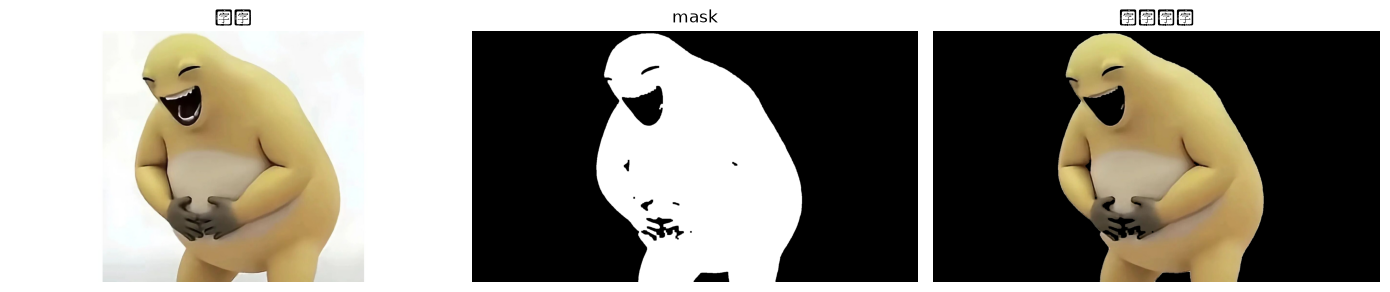

In [7]:
# --- 任务 2.2 ---
# ★★★ 下面两行必须自己填（参考 2.1 的采样结果）★★★
SKIN_LOWER = np.array([14, 40, 70])      # TODO: 奶蛙皮肤的 [H, S, V] 下限
SKIN_UPPER = np.array([50, 255, 255])      # TODO: [H, S, V] 上限

skin_mask=cv2.inRange(hd_hsv, SKIN_LOWER, SKIN_UPPER)
ratio_before=(cv2.countNonZero(skin_mask)/skin_mask.size)
skin_mask=cv2.morphologyEx(skin_mask, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
skin_mask=cv2.morphologyEx(skin_mask, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
ratio_after=(cv2.countNonZero(skin_mask)/skin_mask.size)
print(f"开运算前 skin_mask 占比: {ratio_before:.2%}, 开运算后 skin_mask 占比: {ratio_after:.2%}")
cv2.imwrite('out/hw2_mask.png', skin_mask)
skin_img=cv2.bitwise_and(hd_img, hd_img, mask=skin_mask)
cv2.imwrite('out/hw2_result.png', skin_img)
show(hd_img, skin_mask, skin_img, titles=['原图', 'mask', '抠图结果'], gray_flags=[False, True, False])

# TODO: 存 skin_mask -> out/hw2_mask.png，抠图结果 -> out/hw2_result.png
#   抠图用 cv2.bitwise_and(hd_img, hd_img, mask=skin_mask)
#   显示时别忘了 show(hd_img, skin_mask, skin_img, titles=[...], gray_flags=[False, True, False])

In [8]:
# --- 任务 2.3 ---
cnts,_=cv2.findContours(skin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
biggest = sorted(cnts, key=cv2.contourArea, reverse=True)[0]
x, y, w, h = cv2.boundingRect(biggest)
frog_bbox=(x,y,w,h)
bbox_img=hd_img.copy()
print(f"最大轮廓的外接矩形: (x={x}, y={y}, w={w}, h={h})")
cv2.rectangle(bbox_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
cv2.imwrite('out/hw2_bbox.png', bbox_img)
# TODO: findContours 找轮廓（注意 OpenCV 4.x 返回两个值）
# TODO: 按面积排序，取最大的一个
# TODO: boundingRect 拿外接矩形，打印 (x, y, w, h)
# TODO: 画框并存成 out/hw2_bbox.png
#   面积用 cv2.contourArea(c)，排序用 sorted(cnts, key=cv2.contourArea, reverse=True)

最大轮廓的外接矩形: (x=536, y=11, w=884, h=1069)


True

In [9]:
# --- 任务 2.4（红色分两段） ---
santa_img = cv2.imread('res/nl_santa.png')
santa_hsv = cv2.cvtColor(santa_img, cv2.COLOR_BGR2HSV_FULL)
red_hue_lo = cv2.inRange(santa_hsv, np.array([0, 80, 80]), np.array([14, 255, 255]))
red_hue_hi=cv2.inRange(santa_hsv, np.array([243, 80, 80]), np.array([255, 255, 255]))
red_lo_only=cv2.bitwise_and(santa_img, santa_img, mask=red_hue_lo)
red_both=cv2.bitwise_and(santa_img,santa_img,mask=(red_hue_lo | red_hue_hi))
print(f"第一次红色像素数{red_hue_lo.sum()/255}, 第二次红色像素数{(red_hue_lo | red_hue_hi).sum()/255},\
      相差{((red_hue_lo | red_hue_hi).sum()/255-red_hue_lo.sum()/255)},因为红色跨越了色环两端，只使用一个区间会漏掉另一端的红色")
# TODO: 只用 0~14 做一次红色 mask
# TODO: 再补上 243~255 两段相或
# TODO: 打印两次的像素数（mask.sum()/255），解释差别

第一次红色像素数78521.0, 第二次红色像素数80820.0,      相差2299.0,因为红色跨越了色环两端，只使用一个区间会漏掉另一端的红色


In [10]:
# --- 任务 2.5 ⭐ 压轴：光照稳定性实验 ---
target_xy = (978, 546)
ref_bgr = hd_img[target_xy[1], target_xy[0]].astype(int)
ref_hsv = hd_hsv[target_xy[1], target_xy[0]]

# 在 k=1.0 处标定两组阈值
bgr_lo = np.clip(ref_bgr - 40, 0, 255).astype(np.uint8)      # BGR 区间下限
bgr_up = np.clip(ref_bgr + 40, 0, 255).astype(np.uint8)      # BGR 区间上限
hsv_lo = np.array([max(int(ref_hsv[0]) - 15, 0), 60, 60])       # HSV 区间下限
hsv_up = np.array([int(ref_hsv[0]) + 15, 255, 255])             # HSV 区间上限

print(f'BGR 区间 {bgr_lo} ~ {bgr_up}')
print(f'HSV 区间 {hsv_lo} ~ {hsv_up}')

for k in [0.4,0.7,1.0,1.3]:
    dim_img=np.clip(hd_img*k,0,255).astype(np.uint8)
    dim_hsv=cv2.cvtColor(dim_img, cv2.COLOR_BGR2HSV_FULL)
    dim_bgr=dim_img[target_xy[1], target_xy[0]]
    dim_hsv_px=dim_hsv[target_xy[1], target_xy[0]]
    in_bgr=np.all(dim_bgr>=bgr_lo) and np.all(dim_bgr<=bgr_up)
    in_hsv=np.all(dim_hsv_px>=hsv_lo) and np.all(dim_hsv_px<=hsv_up)
    print(f"k={k:.1f}, BGR={dim_bgr}, HSV={dim_hsv_px}, in BGR range: {in_bgr}, in HSV range: {in_hsv}")
# TODO: 对 k in [0.4, 0.7, 1.0, 1.3] 循环：
#   1) 整图乘 k（记得 np.clip 到 0~255 再 astype(np.uint8)）
#   2) 取 (978,546) 处的 BGR 和 HSV_FULL
#   3) 判断该像素是否落在 BGR 区间内、是否落在 HSV 区间内
#   4) 打印一行，填进上面的表


BGR 区间 [ 93 126 145] ~ [173 206 225]
HSV 区间 [12 60 60] ~ [ 42 255 255]
k=0.4, BGR=[53 66 74], HSV=[26 72 74], in BGR range: False, in HSV range: True
k=0.7, BGR=[ 93 116 129], HSV=[ 27  71 129], in BGR range: False, in HSV range: True
k=1.0, BGR=[133 166 185], HSV=[ 27  72 185], in BGR range: True, in HSV range: True
k=1.3, BGR=[172 215 240], HSV=[ 27  72 240], in BGR range: False, in HSV range: True


In [11]:
# --- 任务 2.6（刻度陷阱） ---
fimg01 = hd_img.astype(np.float32) / 255.0            # 变成 0~1
bright01 = np.clip(fimg01 * 1.5, 0, 1)
cv2.imwrite('out/hw2_float_wrong.png', bright01)  
bright_u8=(bright01*255).astype(np.uint8)
cv2.imwrite('out/hw2_float_right.png', bright_u8)
print(f"直接存的均值: {cv2.imread('out/hw2_float_wrong.png').mean():.2f}, 先乘 255 再存的均值: {cv2.imread('out/hw2_float_right.png').mean():.2f}")
# TODO: ① 直接 cv2.imwrite 存一次 -> out/hw2_float_wrong.png
# TODO: ② 先 (bright01*255).astype(np.uint8) 再存 -> out/hw2_float_right.png
# TODO: 两张都读回来打印均值，解释差异

直接存的均值: 0.95, 先乘 255 再存的均值: 237.24


[ WARN:0@0.866] global loadsave.cpp:1089 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.


**2.5 回答（哪个分量稳定、哪个不稳、BGR 卡阈值会怎样）：**

色相和饱和度这两个分量非常稳定，而明度和bgr三个通道的数值都不稳定，如果使用bgr卡阈值，受环境光影响非常大，系统鲁棒性差，同时也不利于对亮度进行单独控制

**2.6 回答（为什么直接存会出问题）：**
imwrite函数不会自动识别数据类型，而是统一当作uint8,所以float32转换成的0到1数字对应的基本上就是黑色，图像原有信息会几乎全部丢失

---


## 阶段三 · 抠图与贴标（第 4 章）· 10 分

**任务 3.1（3 分）** 验证饱和加法与 NumPy 加法的区别：
造两个 `uint8` 的二维数组 `x = [[200, 200]]`、`y = [[100, 100]]`，
分别打印 `cv2.add(x, y)` 和 `x + y`，解释为什么结果不同。

**任务 3.2（7 分）** 把 `res/logo.png` 贴到 `res/nl_hd01.jpg` 的**右下角**，存成 `out/hw3_logo_paste.png`。

要求按经典四步做：

1. 在底图上取一块与 logo **等大**的 ROI
2. 把 logo 灰度化 + 阈值化，得到 logo 前景的掩膜 `mask`，再 `bitwise_not` 得到 `mask_inv`
3. 用 `mask_inv` 抠出 ROI 的背景部分，用 `mask` 抠出 logo 前景部分
4. 两部分相加，再放回原图 ROI

> ⚠️ 这个 logo 是 **白底 + 深色图案**。想清楚阈值化该用 `THRESH_BINARY` 还是
> `THRESH_BINARY_INV` —— 选错了会把底图那块涂白，logo 反而消失。

In [12]:
# --- 任务 3.1 ---
arr_a = np.array([[200, 200]], np.uint8)
arr_b = np.array([[100, 100]], np.uint8)

print(f"cv2.add(arr_a, arr_b) = {cv2.add(arr_a, arr_b)}")
print(f"arr_a + arr_b = {arr_a + arr_b}")

# TODO: 打印 cv2.add(arr_a, arr_b) 和 arr_a + arr_b，解释差别
#   提示：uint8 最大 255，300 存不下

cv2.add(arr_a, arr_b) = [[255 255]]
arr_a + arr_b = [[44 44]]


In [13]:
# --- 任务 3.2 ---
hd_base = cv2.imread('res/nl_hd01.jpg')
logo_img = cv2.imread('res/logo.png')
lh, lw = logo_img.shape[:2]
print(f'底图 {hd_base.shape},logo_img {logo_img.shape}')

logo_roi=hd_base[hd_base.shape[0]-lh:, hd_base.shape[1]-lw:]
logo_gray=cv2.cvtColor(logo_img, cv2.COLOR_BGR2GRAY)
_, logo_mask = cv2.threshold(logo_gray, 127, 255, cv2.THRESH_BINARY_INV)
logo_mask_inv = cv2.bitwise_not(logo_mask)
bg_part=cv2.bitwise_and(logo_roi, logo_roi, mask=logo_mask_inv)
fg_part=cv2.bitwise_and(logo_img, logo_img, mask=logo_mask)
composited=cv2.add(bg_part, fg_part)
hd_base[hd_base.shape[0]-lh:, hd_base.shape[1]-lw:]=composited
cv2.imwrite('out/hw3_logo_paste.png', hd_base)


# TODO 2: 灰度化 + 阈值化得到 logo_mask，再取反得到 logo_mask_inv
#   先打印 logo_img 灰度的 min/max，判断该用 BINARY 还是 BINARY_INV

# TODO 3: 抠出背景 bg 和前景 fg
# bg = cv2.bitwise_and(logo_roi, logo_roi, mask=logo_mask_inv)
# fg = cv2.bitwise_and(logo_img, logo_img, mask=logo_mask)

# TODO 4: 相加后放回原图 ROI，存成 out/hw3_logo_paste.png

底图 (1080, 1920, 3),logo_img (373, 801, 3)


True

**3.1 回答（两个结果分别是什么、为什么）：**

两个结果分别是（255,255）和（44,44）这是因为cv2.add方法对待溢出是饱和截断，相加超过255就是255,而直接相加会产生回卷，求和会对256进行取模操作。

---


## 阶段四 · 滤波去噪（第 8 章）· 10 分

**任务 4.1（4 分）** 给 `res/nl_classic1.jpg` 加 **3% 的椒盐噪声**
（黑白点各一半，用 `np.random.seed(42)` 保证可复现），
然后分别用**均值、高斯、中值**三种滤波（核都用 5×5）处理，
计算每种结果与**干净原图**的平均绝对差（`np.abs(差分).mean()`），
把三个数打印出来，指出哪个最干净。把对比图存成 `out/hw4_filter_compare.png`。

**任务 4.2（3 分）** 手算题：一个 3×3 邻域里，8 个像素是 100，1 个是白点 255。
分别算出**均值**和**中值**的结果，用这个例子解释**为什么中值滤波专治椒盐噪声**。

**任务 4.3（3 分）** 回答：**双边滤波**和上面三种有什么本质不同？它换来了什么、代价是什么？

In [14]:
# --- 任务 4.1 ---


def add_salt_pepper(image, ratio=0.03):
    """加椒盐噪声：一半黑点一半白点。"""
    noisy = image.copy()
    n = int(image.shape[0] * image.shape[1] * ratio)
    ys = np.random.randint(0, image.shape[0], n)
    xs = np.random.randint(0, image.shape[1], n)
    half = n // 2
    noisy[ys[:half], xs[:half]] = 0
    noisy[ys[half:], xs[half:]] = 255
    return noisy


np.random.seed(42)
scene = cv2.imread('res/nl_classic1.jpg')
noisy = add_salt_pepper(scene, 0.03)

kernel=np.ones((5, 5), np.uint8)
noisy_blur=cv2.blur(noisy, (5, 5))
noisy_gaussian=cv2.GaussianBlur(noisy, (5, 5), 0)
noisy_median=cv2.medianBlur(noisy, 5)
for filt, filt_name in [(noisy_blur, "均值滤波"), (noisy_gaussian, "高斯滤波"), (noisy_median, "中值滤波")]:
    diff = np.abs(filt.astype(np.int16) - scene.astype(np.int16)).mean()
    print(f"{filt_name} 平均绝对差: {diff:.2f}")
print("中值最干净")
compare_img = np.hstack((noisy, noisy_blur, noisy_gaussian, noisy_median))
cv2.imwrite('out/hw4_filter_compare.png', compare_img)


均值滤波 平均绝对差: 4.17
高斯滤波 平均绝对差: 3.99
中值滤波 平均绝对差: 0.68
中值最干净


True

**4.2 回答（手算过程）：**

均值结果大概是117，中值结果是100，中值不会受到椒盐噪声孤立的噪点影响改变结果，不会被异常值带偏，可以做到完美去除噪点而且不影响原图

**4.3 回答：**

双边与其他三种的本质区别是引入了值域权重，换来了边缘不会被模糊的效果，可以实现降噪同时保留边缘，但是代价是计算量大量上升，运行速度变慢，而且调参非常难，多次双边还可能出现边缘分层，呈卡通化

---


## 阶段五 · 摆正与标注（第 9、10 章）· 13 分

**任务 5.1（4 分）** 把 `out/card.png` **逆时针旋转 30°**，存成 `out/hw5_rotate30.png`。
（提示：`cv2.getRotationMatrix2D(中心, 角度, 缩放)`，角度为正表示逆时针）

**任务 5.2（4 分）** 把 `res/nl_hd01.jpg` 缩放到**宽 640**（保持宽高比），
用 `cv2.INTER_AREA` 插值，打印缩放前后的 shape。
回答：**缩小图片时推荐用哪个插值方法？放大呢？**

**任务 5.3（5 分）** 在上一步缩放后的图上，把奶蛙**框出来并打上标签**：

- 用阶段二检测到的 bbox `(537, 13, 882, 1067)`（这是**原图**坐标，
  缩放后要一起乘 `640/1920`）
- 画一个绿色矩形框
- 在框内顶部写一行文字 `Nailong 92%`
- 存成 `out/hw5_annotate.png`


In [15]:
# --- 任务 5.1 ---
card = cv2.imread('out/card.png')
ch, cw = card.shape[:2]
rot_mtx = cv2.getRotationMatrix2D((cw // 2, ch // 2), 30, 1.0) 
card_rot = cv2.warpAffine(card, rot_mtx, (cw, ch))
cv2.imwrite('out/hw5_rotate30.png', card_rot)      


True

In [16]:
# --- 任务 5.2 ---
hd_img = cv2.imread('res/nl_hd01.jpg')
print(f"缩放前 shape: {hd_img.shape}")
ratio =hd_img.shape[1]/640
small_img=cv2.resize(hd_img,(640,int(hd_img.shape[0]/ratio)), interpolation=cv2.INTER_AREA)
print(f"缩放后 shape: {small_img.shape}")


缩放前 shape: (1080, 1920, 3)
缩放后 shape: (360, 640, 3)


In [17]:
# --- 任务 5.3 ---
hd_img = cv2.imread('res/nl_hd01.jpg')
scale = 640 / hd_img.shape[1]
small_img = cv2.resize(hd_img, (640, int(hd_img.shape[0] * scale)),
                       interpolation=cv2.INTER_AREA)

bx, by, bw, bh = [int(round(v * scale)) for v in (537, 13, 882, 1067)]
cv2.rectangle(small_img, (bx, by), (bx + bw, by + bh), (0, 255, 0), 3)
cv2.putText(small_img, 'Nailong 92%', (bx + 8, by + 30),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
cv2.imwrite('out/hw5_annotate.png', small_img)

# TODO: 把原图 bbox (537, 13, 882, 1067) 按 scale 缩放成缩放图上的坐标
# TODO: 画绿色矩形框（线宽 3）
# TODO: 在框内顶部写字 'Nailong 92%'，字号 0.7，黑色
#   提示：cv2.putText 的 org 是文字「左下角」坐标
# TODO: 存成 out/hw5_annotate.png


True

**5.2 回答（缩小 / 放大分别推荐什么插值）：**

缩小时推荐采用INTER_AREA方法，可以有效抑制摩尔纹，放大时取决于具体场景，INTER_LINEAR方法速度和质量比较均衡，而INTER_CUBIC画质更好，但是速度不快

---


## 阶段六 · 封装成类（第 11 章）· 15 分

把前面散装的检测逻辑收拾成一个类 `NailongDetector`。

**要求实现以下接口：**

| 成员 | 要求 |
| --- | --- |
| `__init__(self, lower, upper, min_area=2000, kernel_size=7)` | 阈值区间、最小面积、开运算核大小 |
| `set_roi(self, x, y, w, h)` | 设定只在 ROI 内检测（不设 = 全图） |
| `mask(self, bgr)` | 返回清理后的掩膜 |
| `detect(self, bgr)` | 返回 `[(x, y, w, h, area), ...]`，**按面积从大到小排序**，坐标是**原图坐标** |
| `annotate(self, bgr)` | 在原图上画框 + 写字，返回新图（**不要改原图**） |
| `from_config(cls, path)` | 类方法，从 JSON 文件读阈值构造实例 |

**硬性要求：**

1. 阈值区间必须用**私有属性**（`self.__lower` / `self.__upper`）保存 —— 外部能随手改，队友一个手滑就把检测搞崩了
2. `set_roi` 之后，`detect` 返回的坐标必须是**原图坐标系**下的（别忘了把 ROI 偏移加回去）
3. `annotate` 不能修改传进来的原图

**测试（写在同一格或下一格）：**

- 用 `lower=(15,60,60)`、`upper=(48,255,255)` 造一个实例，打印它在 `nl_hd01.jpg` 上检出的目标数
- 调 `set_roi(0, 540, 1920, 540)`，再打印一次目标数
- 构造一个 JSON 配置文件，用 `from_config` 读进来，确认能正常构造

**回答**：为什么 `set_roi` 之后坐标要加回偏移？不加会怎样？

In [18]:
# --- 任务 6 ---


class NailongDetector:
    """按 HSV 区间检测奶蛙皮肤，并负责去噪、定位、标注。"""

    def __init__(self, lower, upper, min_area=2000, kernel_size=7):
        self.__lower = np.array(lower, np.uint8)    
        self.__upper = np.array(upper, np.uint8)
        self.__min_area = min_area
        self.__kernel = np.ones((kernel_size, kernel_size), np.uint8)
        self.__roi = None  #
      
    def set_roi(self, x, y, w, h):
        self.__roi = (x, y, w, h)
       
    def mask(self, bgr):
        hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV_FULL)
        if self.__roi is not None:
            roi=hsv[self.__roi[1]:self.__roi[1]+self.__roi[3], self.__roi[0]:self.__roi[0]+self.__roi[2]]
            roi_mask=cv2.inRange(roi, self.__lower, self.__upper)
            roi_mask = cv2.morphologyEx(roi_mask, cv2.MORPH_OPEN, self.__kernel)
            return roi_mask
        else:
            full_mask=cv2.inRange(hsv, self.__lower, self.__upper)
            full_mask = cv2.morphologyEx(full_mask, cv2.MORPH_OPEN, self.__kernel)
            return full_mask

       
    def detect(self, bgr):
        mask=self.mask(bgr)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        valid_contours = [i for i in contours if cv2.contourArea(i) >= self.__min_area]
        result=[]
        for cont in valid_contours:
            x, y, w, h = cv2.boundingRect(cont)
            if self.__roi is not None:
                x += self.__roi[0]
                y += self.__roi[1]
            area = cv2.contourArea(cont)
            result.append((x, y, w, h, area))
        result.sort(key=lambda x: x[4], reverse=True)
        return result
        

    def annotate(self, bgr, color=(0, 255, 0), thickness=3):
        bgr2=bgr.copy()
        for x, y, w, h, area in self.detect(bgr):
            cv2.rectangle(bgr2, (x, y), (x + w, y + h), color, thickness)
            cv2.putText(bgr2, f'{int(area)}', (x + 5, y + 25),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
        return bgr2
     
    @classmethod
    def from_config(cls, path):
        with open(path, 'r', encoding='utf-8') as f:
            config = json.load(f)
            return cls(config['lower'], config['upper'], config.get('min_area', 2000), config.get('kernel_size', 7))
        
      

In [19]:
# --- 任务 6 测试 ---
# TODO: 构造实例，打印在 hd01 上的目标数
# TODO: set_roi(0, 540, 1920, 540) 后再打印一次
# TODO: 写一个 JSON 配置，用 from_config 读进来验证
import json
cfg = {'lower': [15, 60, 60], 'upper': [48, 255, 255], 'min_area': 2000, 'kernel_size': 7}
with open('out/hw6_config.json', 'w', encoding='utf-8') as fp:
    json.dump(cfg, fp)
test_detector = NailongDetector.from_config('out/hw6_config.json')
test_img = cv2.imread('res/nl_hd01.jpg', cv2.IMREAD_COLOR)
print(f"目标数: {len(test_detector.detect(test_img))}")
test_detector.set_roi(0, 540, 1920, 540)
print(f"目标数: {len(test_detector.detect(test_img))}")

目标数: 1
目标数: 1


**回答（为什么 set_roi 后坐标要加回偏移）：**

如果不加上偏移量，那么findcontours找到的轮廓就是相对于roi取出的那片区域而言的，但是在annotate这个函数里我们画图时选择的画布是一整张原图，很明显这样会导致矩形框不到正确的对象

---


## 实验小结（100~200 字）


1.坑：这次大作业我踩了不少坑，最大的一个就是命名问题，由于我没有注意这一点，导致程序里面第一遍出现了无数个img,无数个mask,知道我做到5.3画矩形的时候才发现莫名其妙画布上出现了两个框，还怎么改都改不掉，后来我才知道这是由于我写了两个一样的mask名字，在我调试的时候返回去运行2.2,结果这个时候那一栏里面findcontours拿到的mask是logo任务里面的，bbox直接不一样，要不是ai提醒我我应该怎么也发现不了。

2.我觉得，对处理取掩码的这个知识点最重要，就目前的学习来看，最重要的就是怎么在图像中找到并且识别我们想要的那个roi,而掩码正是这一操作的核心，目前学到的整个流程，读图——滤波——二值化——形态学处理——抠图，核心中的核心就是对掩码的获取，当然，在获取掩码的众多步骤中，我觉得最核心还是阈值，无论是inrange还是threshold,这都是我们获取掩码图的基础，这个点不是最难的，但绝对是最重要的。

3.目前来看，我不懂的有这几点（1），怎么调参我不是很明白，在阶段二的颜色识别任务里让我取区间我搞了几次都效果不好，最后还是借助了ai工具让他帮我找才基本可以。（2），kernel核的选择，我对于不同形状，不同作用的核怎么选择不是很懂，我尝试去研究了一下，结果发现我的数学水平好像还不太行。（3）这个json文件我不了解，这次作业碰到也是临时学了学，我只能说还在学习。
